# GreenTrail Outdoors | Exploratory Retail Analysis

**Python portfolio study · 2024–2025**  
**Dataset:** Synthetic retail operations covering 150 stores, with the original promotion observations retained separately.

## Objective
To examine transaction values, seasonality, regional sales, customer segments, promotional activity, and product profitability. The analysis is descriptive; simulated transactions cannot establish the causal effect of promotions.

## Tools and data
`pandas`, `NumPy`, `Matplotlib`, `SciPy`; CSV files in `GreenTrail_Expanded/`. The notebook expects the same project-folder layout as the GitHub repository.

## 1. Data preparation and quality checks
We begin by confirming row counts and data types, converting dates, checking missing values and duplicates, and retaining missing promotion IDs as non-promotional transactions.


In [1]:

# GreenTrail Outdoors
# Python Exploratory Data Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("GreenTrail Python environment ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


GreenTrail Python environment ready!
Pandas version: 3.0.6
NumPy version: 2.5.4


In [2]:

# Load GreenTrail transaction data

from pathlib import Path

data_path = Path("../../GreenTrail_Expanded/transactions.csv")

transactions = pd.read_csv(data_path)

# Preview the first five records
transactions.head()


,transaction_id,store_id,transaction_date,segment_id,promotion_id,transaction_total_usd,record_origin
0,1,1,2024-01-03,2,NaN,32.66,SYNTHETIC
1,2,1,2024-01-03,2,NaN,321.39,SYNTHETIC
2,3,1,2024-01-03,1,NaN,75.87,SYNTHETIC
3,4,1,2024-01-03,3,NaN,40.03,SYNTHETIC
4,5,1,2024-01-04,4,NaN,145.65,SYNTHETIC


In [3]:

# Analysis 1: Dataset dimensions

print("Number of transactions:", transactions.shape[0])
print("Number of columns:", transactions.shape[1])


Number of transactions: 426602
Number of columns: 7


In [4]:

# Analysis 2: Check data types

transactions.info()


<class 'pandas.DataFrame'>
RangeIndex: 426602 entries, 0 to 426601
Data columns (total 7 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         426602 non-null  int64  
 1   store_id               426602 non-null  int64  
 2   transaction_date       426602 non-null  str    
 3   segment_id             426602 non-null  int64  
 4   promotion_id           19938 non-null   float64
 5   transaction_total_usd  426602 non-null  float64
 6   record_origin          426602 non-null  str    
dtypes: float64(2), int64(3), str(2)
memory usage: 22.8 MB


In [5]:

# Analysis 3: Check missing values

transactions.isnull().sum()


transaction_id                0
store_id                      0
transaction_date              0
segment_id                    0
promotion_id             406664
transaction_total_usd         0
record_origin                 0
dtype: int64

In [6]:

# Analysis 4: Convert transaction dates

transactions["transaction_date"] = pd.to_datetime(
    transactions["transaction_date"]
)

print(transactions["transaction_date"].dtype)

print("First date:", transactions["transaction_date"].min())
print("Last date:", transactions["transaction_date"].max())


datetime64[us]
First date: 2024-01-01 00:00:00
Last date: 2025-12-31 00:00:00


In [7]:

# Analysis 5: Transaction value summary

transactions["transaction_total_usd"].describe().round(2)


count    426602.00
mean        208.66
std         156.81
min          12.76
25%          90.26
50%         170.40
75%         276.14
max        1545.98
Name: transaction_total_usd, dtype: float64

In [8]:

# Analysis 6: Duplicate transaction IDs

duplicates = transactions["transaction_id"].duplicated().sum()

print("Duplicate transaction IDs:", duplicates)


Duplicate transaction IDs: 0


In [9]:

# Analysis 7: Classify transaction types

transactions["transaction_type"] = np.where(
    transactions["promotion_id"].notna(),
    "Promotional",
    "Non-Promotional"
)

transactions["transaction_type"].value_counts()


transaction_type
Non-Promotional    406664
Promotional         19938
Name: count, dtype: int64

## 2. Sales patterns and transaction distributions
The following charts describe monthly sales, purchase-value distributions, annual results and weekday variation. Differences in monthly totals should be interpreted in light of month length and store activity.


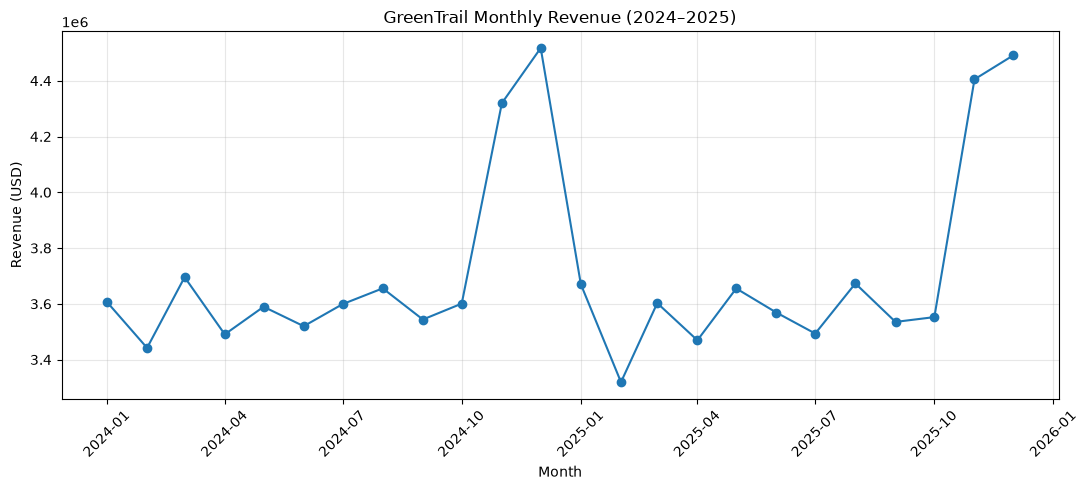

In [10]:

# Analysis 8: Monthly revenue trends

monthly_sales = (
    transactions
    .groupby(
        transactions["transaction_date"].dt.to_period("M")
    )["transaction_total_usd"]
    .sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("GreenTrail Monthly Revenue (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


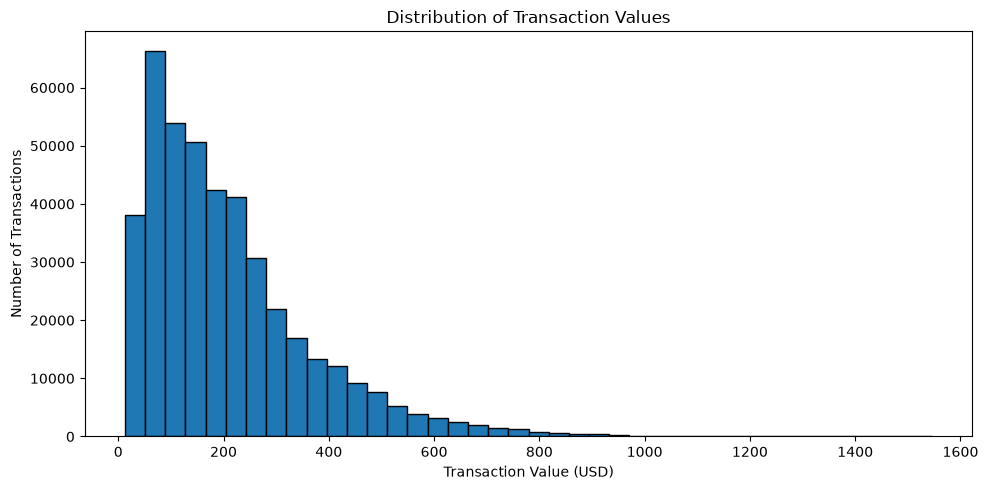

count    426602.00
mean        208.66
std         156.81
min          12.76
25%          90.26
50%         170.40
75%         276.14
max        1545.98
Name: transaction_total_usd, dtype: float64


In [11]:

# Analysis 9: Transaction value distribution

plt.figure(figsize=(10, 5))

plt.hist(
    transactions["transaction_total_usd"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Transaction Values")
plt.xlabel("Transaction Value (USD)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

print(
    transactions["transaction_total_usd"]
    .describe()
    .round(2)
)


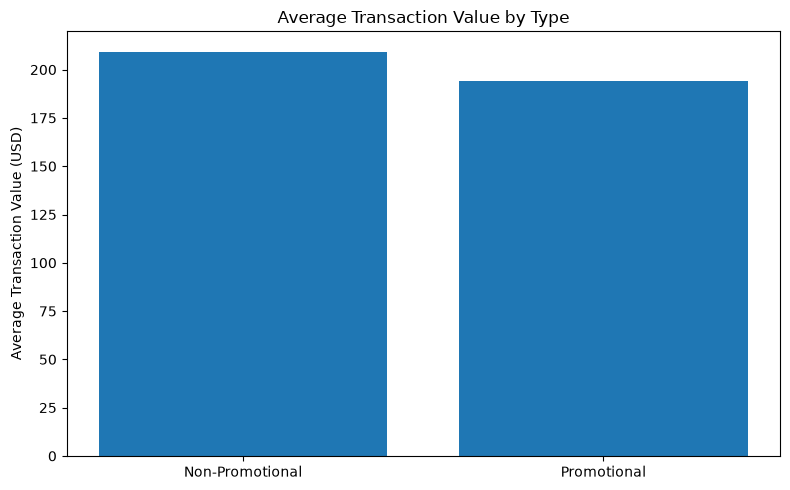

transaction_type
Non-Promotional    209.36
Promotional        194.35
Name: transaction_total_usd, dtype: float64


In [12]:

# Analysis 10: Average transaction value by type

average_spending = (
    transactions
    .groupby("transaction_type")[
        "transaction_total_usd"
    ]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.bar(
    average_spending.index,
    average_spending.values
)

plt.title("Average Transaction Value by Type")
plt.ylabel("Average Transaction Value (USD)")
plt.tight_layout()
plt.show()

print(average_spending.round(2))


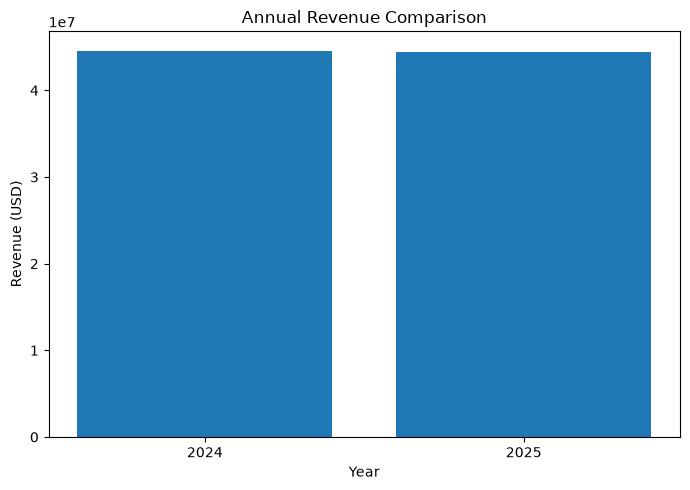

transaction_date
2024    44580140.73
2025    44435128.58
Name: transaction_total_usd, dtype: float64


In [13]:

# Analysis 11: Yearly revenue

yearly_sales = (
    transactions
    .groupby(
        transactions["transaction_date"].dt.year
    )["transaction_total_usd"]
    .sum()
)

plt.figure(figsize=(7, 5))

plt.bar(
    yearly_sales.index.astype(str),
    yearly_sales.values
)

plt.title("Annual Revenue Comparison")
plt.xlabel("Year")
plt.ylabel("Revenue (USD)")
plt.tight_layout()
plt.show()

print(yearly_sales.round(2))


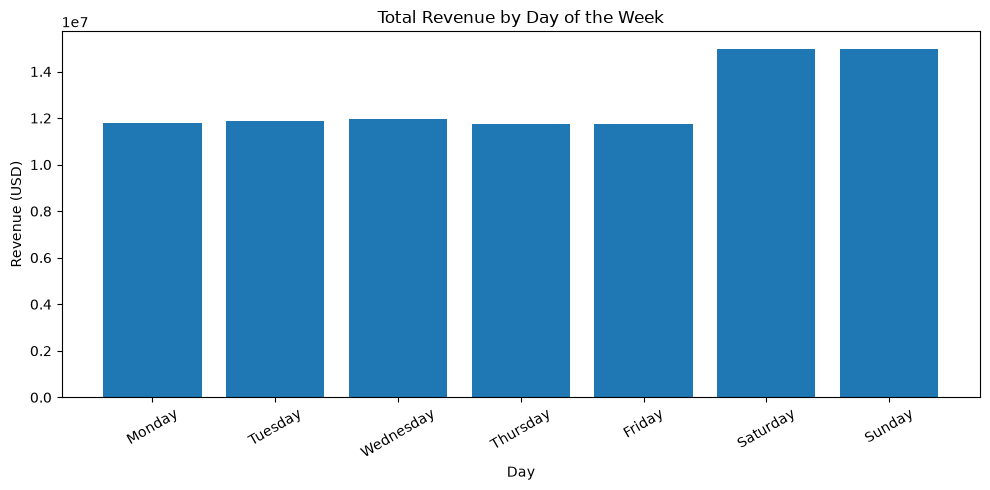

In [14]:

# Analysis 12: Revenue by day of the week

transactions["day_of_week"] = (
    transactions["transaction_date"].dt.day_name()
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_revenue = (
    transactions
    .groupby("day_of_week")["transaction_total_usd"]
    .sum()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))

plt.bar(
    daily_revenue.index,
    daily_revenue.values
)

plt.title("Total Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 3. Store and customer performance
Regional sales are normalised by the number of stores to avoid treating regions with more outlets as automatically more productive. Segment results describe revenue concentration, not individual-customer lifetime value.


           total_revenue  total_stores  revenue_per_store
region                                                   
Midwest      18400446.20            27          681498.01
Northeast    13075272.66            23          568490.12
South        32364556.44            60          539409.27
West         25174994.01            40          629374.85


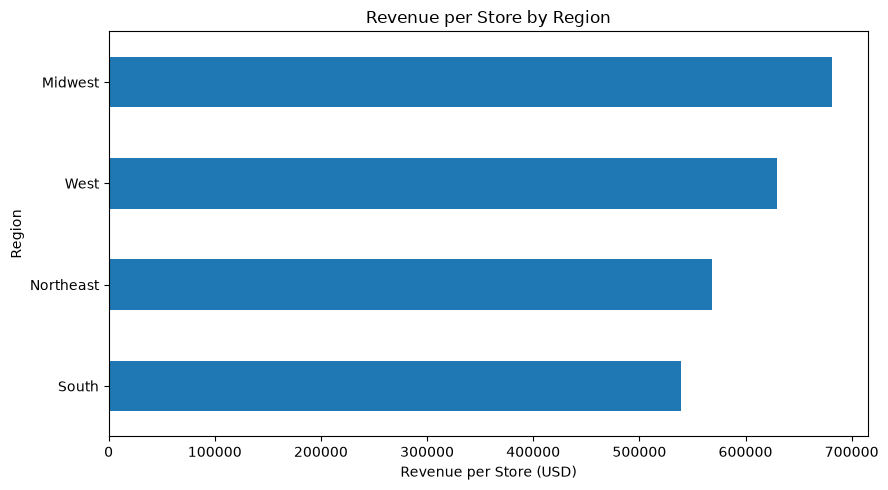

In [15]:

# Analysis 13: Regional revenue

stores = pd.read_csv(
    "../../GreenTrail_Expanded/stores.csv"
)

sales_data = transactions.merge(
    stores[["store_id", "region", "store_type"]],
    on="store_id",
    how="left"
)

regional_sales = (
    sales_data
    .groupby("region")
    .agg(
        total_revenue=("transaction_total_usd", "sum"),
        total_stores=("store_id", "nunique")
    )
)

regional_sales["revenue_per_store"] = (
    regional_sales["total_revenue"] /
    regional_sales["total_stores"]
)

print(regional_sales.round(2))

regional_sales["revenue_per_store"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Revenue per Store by Region")
plt.xlabel("Revenue per Store (USD)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


segment_name
Casual Shoppers        14242287.36
Eco-Conscious          16003577.60
Family Shoppers        16052964.97
Outdoor Enthusiasts    20521463.18
Value Seekers          22194976.20
Name: transaction_total_usd, dtype: float64


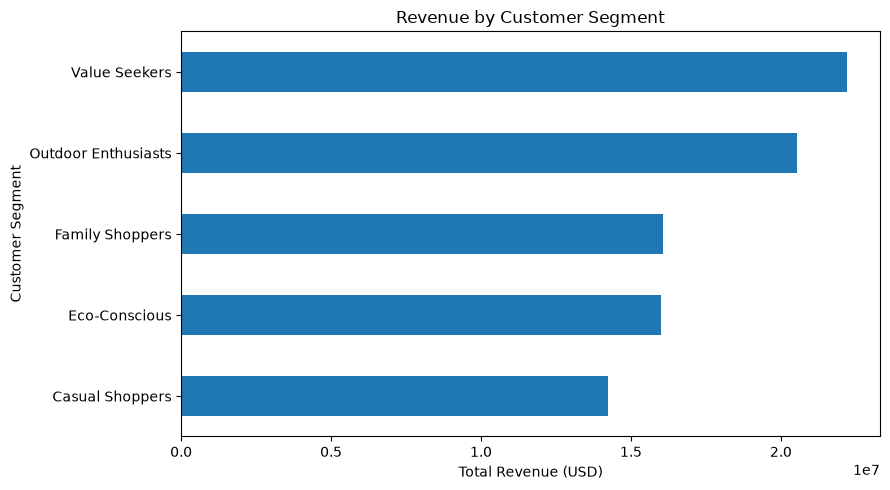

In [16]:

# Analysis 14: Customer segment performance

segments = pd.read_csv(
    "../../GreenTrail_Expanded/customer_segments.csv"
)

customer_sales = transactions.merge(
    segments[["segment_id", "segment_name"]],
    on="segment_id",
    how="left"
)

segment_revenue = (
    customer_sales
    .groupby("segment_name")["transaction_total_usd"]
    .sum()
    .sort_values()
)

print(segment_revenue.round(2))

segment_revenue.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Total Revenue (USD)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()


transaction_type
Non-Promotional    95.33
Promotional         4.67
Name: count, dtype: float64


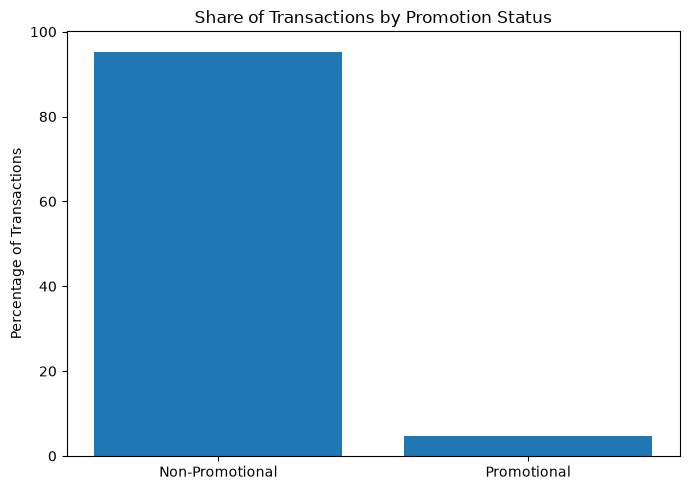

In [17]:

# Analysis 15: Promotional transaction share

transaction_counts = (
    transactions["transaction_type"]
    .value_counts()
)

transaction_pct = (
    transaction_counts /
    transaction_counts.sum() * 100
)

print(transaction_pct.round(2))

plt.figure(figsize=(7, 5))

plt.bar(
    transaction_pct.index,
    transaction_pct.values
)

plt.title("Share of Transactions by Promotion Status")
plt.ylabel("Percentage of Transactions")
plt.tight_layout()
plt.show()


## 4. Promotional performance
A transaction with a recorded promotion ID is classified as promotional. These comparisons do not control for store, customer, product or seasonal differences, and **should not be interpreted as incremental lift or ROI**.


promotion_type
Buy-One-Get-One             728074.85
Discount                    744505.25
Special Event               749923.68
Loyalty Reward              792030.18
Sustainability Spotlight    860345.10
Name: transaction_total_usd, dtype: float64


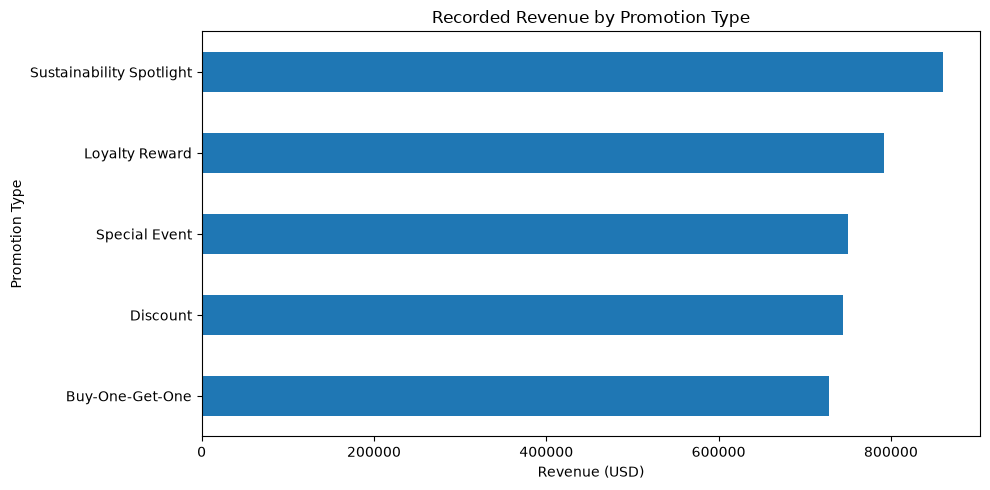

In [18]:

# Analysis 16: Promotional revenue by type

promotions = pd.read_csv(
    "../../GreenTrail_Expanded/promotions.csv"
)

promotion_sales = transactions.merge(
    promotions[["promotion_id", "promotion_type"]],
    on="promotion_id",
    how="inner"
)

promotion_revenue = (
    promotion_sales
    .groupby("promotion_type")["transaction_total_usd"]
    .sum()
    .sort_values()
)

print(promotion_revenue.round(2))

promotion_revenue.plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Recorded Revenue by Promotion Type")
plt.xlabel("Revenue (USD)")
plt.ylabel("Promotion Type")
plt.tight_layout()
plt.show()


promotion_type
Discount                    171.39
Buy-One-Get-One             181.07
Loyalty Reward              203.19
Special Event               206.65
Sustainability Spotlight    212.64
Name: transaction_total_usd, dtype: float64


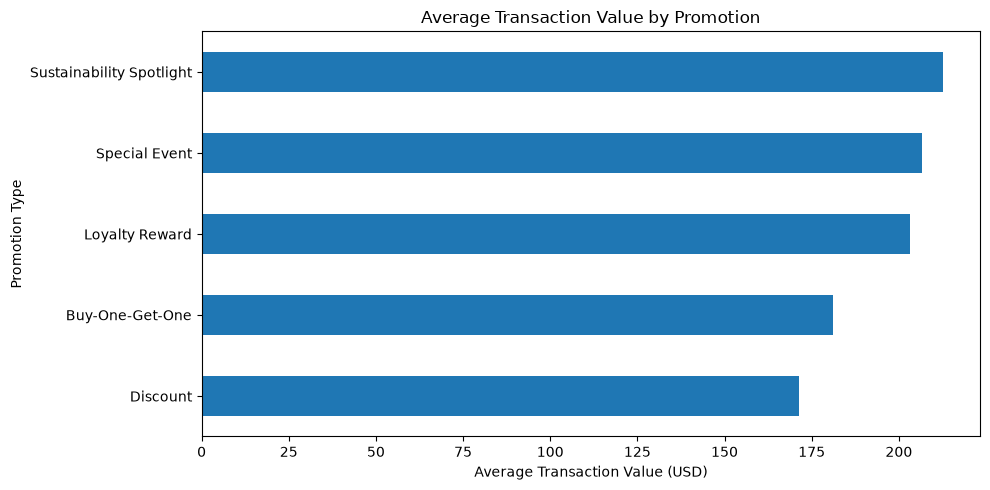

In [19]:

# Analysis 17: Average transaction value by promotion

promotion_average = (
    promotion_sales
    .groupby("promotion_type")["transaction_total_usd"]
    .mean()
    .sort_values()
)

print(promotion_average.round(2))

promotion_average.plot(
    kind="barh",
    figsize=(10, 5)
)

plt.title("Average Transaction Value by Promotion")
plt.xlabel("Average Transaction Value (USD)")
plt.ylabel("Promotion Type")
plt.tight_layout()
plt.show()


## 5. Traffic and sales relationship
Traffic and revenue are first aligned at the store–day level. The resulting Pearson correlation measures linear association only; it does not establish whether traffic caused sales changes.


In [20]:

# Analysis 18: Store traffic and sales

traffic = pd.read_csv(
    "../../GreenTrail_Expanded/daily_store_traffic.csv"
)

traffic["date"] = pd.to_datetime(traffic["date"])

# Calculate revenue per store per day
daily_sales = (
    transactions
    .groupby(["store_id", "transaction_date"])[
        "transaction_total_usd"
    ]
    .sum()
    .reset_index()
)

# Combine sales and traffic
traffic_sales = traffic.merge(
    daily_sales,
    left_on=["store_id", "date"],
    right_on=["store_id", "transaction_date"],
    how="left"
)

traffic_sales["transaction_total_usd"] = (
    traffic_sales["transaction_total_usd"].fillna(0)
)

# Calculate the correlation
correlation = traffic_sales[
    ["visits", "transaction_total_usd"]
].corr()

print(correlation)


                         visits  transaction_total_usd
visits                 1.000000               0.485869
transaction_total_usd  0.485869               1.000000


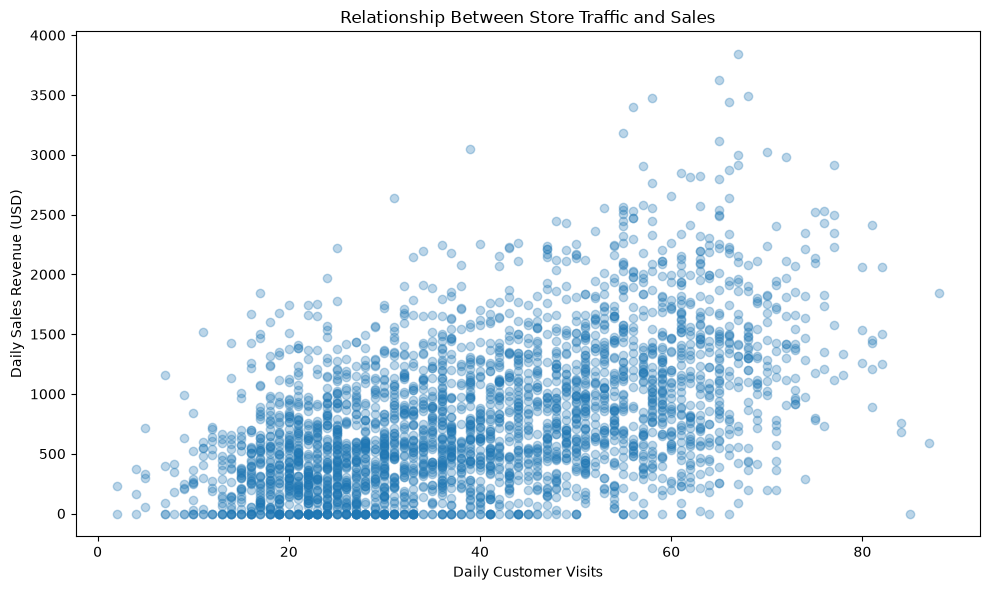

In [21]:

# Analysis 19: Traffic vs sales scatter plot

sample_data = traffic_sales.sample(
    n=3000,
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    sample_data["visits"],
    sample_data["transaction_total_usd"],
    alpha=0.3
)

plt.title("Relationship Between Store Traffic and Sales")
plt.xlabel("Daily Customer Visits")
plt.ylabel("Daily Sales Revenue (USD)")
plt.tight_layout()
plt.show()


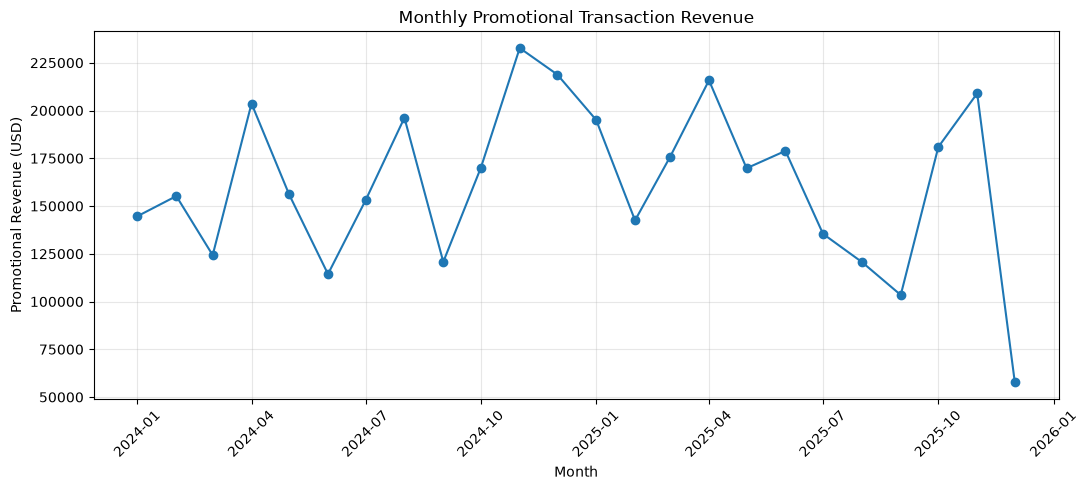

In [22]:

# Analysis 20: Monthly promotional revenue

promotion_sales = promotion_sales.copy()

promotion_sales["transaction_date"] = pd.to_datetime(
    promotion_sales["transaction_date"]
)

monthly_promo = (
    promotion_sales
    .groupby(
        promotion_sales["transaction_date"].dt.to_period("M")
    )["transaction_total_usd"]
    .sum()
)

monthly_promo.index = monthly_promo.index.to_timestamp()

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_promo.index,
    monthly_promo.values,
    marker="o"
)

plt.title("Monthly Promotional Transaction Revenue")
plt.xlabel("Month")
plt.ylabel("Promotional Revenue (USD)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Product category profitability
Gross profit is selling revenue less the recorded cost of goods sold. Gross margin excludes operational expenses and marketing costs.


In [23]:

# Analysis 21: Product category profitability

products = pd.read_csv(
    "../../GreenTrail_Expanded/products.csv"
)

transaction_lines = pd.read_csv(
    "../../GreenTrail_Expanded/transaction_lines.csv"
)

product_sales = transaction_lines.merge(
    products[["product_id", "category"]],
    on="product_id",
    how="left"
)

product_sales["revenue"] = (
    product_sales["quantity"] *
    product_sales["unit_price_paid_usd"]
)

product_sales["gross_profit"] = (
    product_sales["quantity"] *
    (
        product_sales["unit_price_paid_usd"] -
        product_sales["unit_cost_usd"]
    )
)

category_profit = (
    product_sales
    .groupby("category")
    .agg(
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

category_profit["gross_margin_pct"] = (
    category_profit["gross_profit"] /
    category_profit["revenue"] * 100
)

print(category_profit.round(2))


                 revenue  gross_profit  gross_margin_pct
category                                                
Accessories   9908119.99    4557925.65             46.00
Apparel       8936832.65    3799659.04             42.52
Camping      22360234.20   10900940.11             48.75
Equipment    22004446.97   10208565.40             46.39
Footwear     25805635.50   12045771.84             46.68


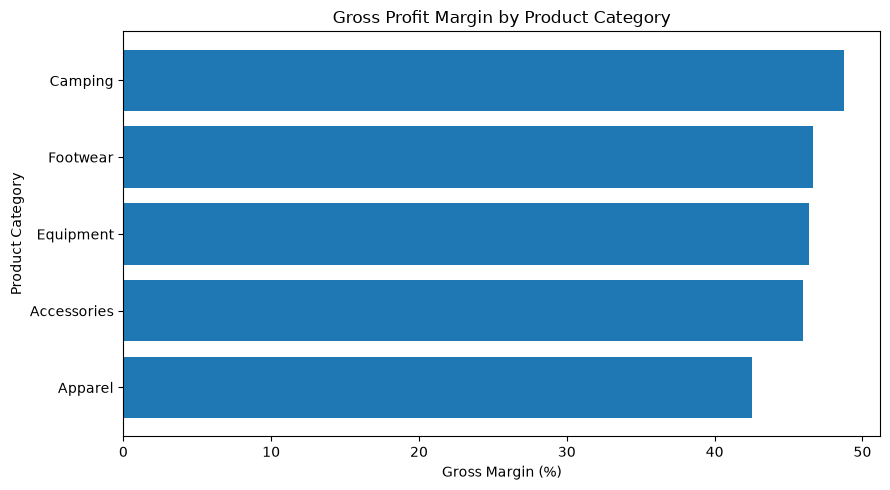

In [24]:

# Analysis 22: Gross margin comparison

margins = (
    category_profit["gross_margin_pct"]
    .sort_values()
)

plt.figure(figsize=(9, 5))

plt.barh(
    margins.index,
    margins.values
)

plt.title("Gross Profit Margin by Product Category")
plt.xlabel("Gross Margin (%)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


## 7. Distribution checks and statistical comparison
High-value transactions identified by the IQR method are candidates for investigation, not automatic errors. Welch’s t-test provides an exploratory comparison between promotion-linked and non-promotion-linked transaction values; transaction-level independence may not hold because observations are clustered by stores and customers.


In [25]:

# Analysis 23: Identify transaction outliers

q1 = transactions["transaction_total_usd"].quantile(0.25)
q3 = transactions["transaction_total_usd"].quantile(0.75)

iqr = q3 - q1

upper_limit = q3 + (1.5 * iqr)

outliers = transactions[
    transactions["transaction_total_usd"] > upper_limit
]

print("Upper outlier threshold:", round(upper_limit, 2))
print("Number of potential outliers:", len(outliers))

print(
    "Percentage of transactions:",
    round(len(outliers) / len(transactions) * 100, 2)
)


Upper outlier threshold: 554.96
Number of potential outliers: 16621
Percentage of transactions: 3.9


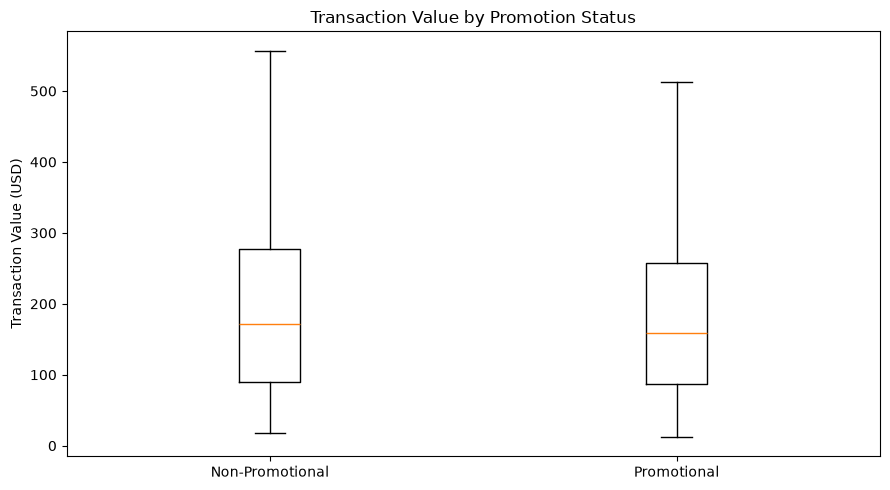

In [26]:

# Analysis 24: Promotional vs regular spending

promo_values = transactions[
    transactions["transaction_type"] == "Promotional"
]["transaction_total_usd"]

regular_values = transactions[
    transactions["transaction_type"] == "Non-Promotional"
]["transaction_total_usd"]

plt.figure(figsize=(9, 5))

plt.boxplot(
    [regular_values, promo_values],
    tick_labels=["Non-Promotional", "Promotional"],
    showfliers=False
)

plt.title("Transaction Value by Promotion Status")
plt.ylabel("Transaction Value (USD)")
plt.tight_layout()
plt.show()


In [27]:

# Analysis 25: Welch's t-test

from scipy import stats

t_statistic, p_value = stats.ttest_ind(
    regular_values,
    promo_values,
    equal_var=False
)

print("Non-promotional average:", round(regular_values.mean(), 2))
print("Promotional average:", round(promo_values.mean(), 2))

print("T-statistic:", round(t_statistic, 3))
print("P-value:", round(p_value, 6))


Non-promotional average: 209.36
Promotional average: 194.35
T-statistic: 14.237
P-value: 0.0


## 8. Reconciliation and executive KPIs
Transaction and line-item revenue should reconcile to the same total. We compare the Python outputs to the completed SQL analysis before reporting summary KPIs.


In [28]:

# Analysis 26: Financial reconciliation

python_revenue = transactions[
    "transaction_total_usd"
].sum()

line_revenue = product_sales["revenue"].sum()

python_gross_profit = product_sales[
    "gross_profit"
].sum()

print("Transaction revenue:", round(python_revenue, 2))
print("Line-item revenue:", round(line_revenue, 2))
print("Revenue difference:", round(python_revenue - line_revenue, 2))
print("Gross profit:", round(python_gross_profit, 2))


Transaction revenue: 89015269.31
Line-item revenue: 89015269.31
Revenue difference: 0.0
Gross profit: 41512862.04


In [29]:

# Analysis 27: Executive KPI summary

total_revenue = transactions["transaction_total_usd"].sum()
total_transactions = len(transactions)
average_transaction = transactions["transaction_total_usd"].mean()
gross_profit = product_sales["gross_profit"].sum()

gross_margin = gross_profit / total_revenue * 100

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue (USD)",
        "Total Transactions",
        "Average Transaction Value (USD)",
        "Gross Profit (USD)",
        "Gross Margin (%)"
    ],
    "Value": [
        round(total_revenue, 2),
        total_transactions,
        round(average_transaction, 2),
        round(gross_profit, 2),
        round(gross_margin, 2)
    ]
})

kpi_summary


,KPI,Value
0,Total Revenue (USD),89015269.31
1,Total Transactions,426602.00
2,Average Transaction Value (USD),208.66
3,Gross Profit (USD),41512862.04
4,Gross Margin (%),46.64


## 9. Findings and interpretation

| Finding | Result | Interpretation |
|---|---:|---|
| Revenue | $89.02 million | Recorded revenue in the synthetic transaction dataset |
| Gross profit | $41.51 million | Gross margin of 46.64%, excluding operating and promotional expenses |
| Promotional transaction share | 4.67% | Share of transactions carrying a promotion ID; not campaign exposure |
| Average value: non-promotional | $209.36 | Higher observed transaction value than promotion-linked purchases |
| Average value: promotional | $194.35 | Difference is descriptive, not a causal promotion effect |
| Traffic–sales correlation | 0.486 | Moderate positive store-day association in the simulated data |
| Potential high-value outliers | 3.90% | Requires business context before exclusion |
| Data reconciliation | $0.00 difference | Revenue matches between transactions and line items |

### Implications for GreenTrail

**Product economics.** Footwear contributes the largest absolute category revenue, while camping has the highest category gross margin (48.75%). Further campaign tests should use gross profit, not revenue alone, as a decision criterion.

**Promotional targeting.** Sustainability Spotlight has the highest revenue associated with labelled promotional transactions; however, campaign exposure, costs, timing and an appropriate control group are required before ranking campaigns by incremental return.

**Store performance.** The Midwest has the highest observed revenue per store. Differences in store size, trading days and location should be considered before treating this as evidence of stronger operations.

### Limitations

- All expanded operating records are synthetic and should not be presented as real company performance.
- Promotion comparisons are observational and do not establish causality or return on investment.
- The t-test is exploratory; records may be clustered, violating assumptions of independent observations.
- Inventory stockout data contain no nonzero stockout days and cannot support stockout-related conclusions.
- The traffic-sales correlation may reflect shared influences such as store scale, time and seasonality.

### Recommendations for subsequent work

1. Use a controlled test with comparable stores to estimate incremental promotional profit.
2. Compare category and store performance using normalised measures alongside aggregate revenue.
3. Develop a Power BI dashboard highlighting sales, category margins, promotion activity and traffic, with visible synthetic-data labelling.

*Source: GreenTrail expanded synthetic dataset. Analysis prepared for a portfolio case study.*
